# Praktikum Pertemuan 4 - Text Preprocessing II
Stemming, Normalisasi, dan perbandingan dua pipeline
NAMA : MUHAMMAD ADITYA RACHMAN
NPM : 2405040018

## 0. Persiapan

In [1]:
import re
import pandas as pd
from collections import Counter

In [2]:
df = pd.read_csv('dataset_ulasan_laptop_100.csv', keep_default_na=False, dtype=str)
teks = df['reviewContent'].tolist()     # daftar 100 ulasan

---
# BAGIAN 1 - PIPELINE A
Cleaning, Case Folding, Tokenisasi, Stopword

In [3]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

stopword_a = set(StopWordRemoverFactory().get_stop_words()) 
print('Jumlah stopword:', len(stopword_a))

Jumlah stopword: 123


### A.1 Cleaning
Membuang link, tag HTML, tanda baca, simbol, dan spasi berlebih.

In [4]:
a_cleaning = []
for t in teks:
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)  
    t = re.sub(r'<[^>]+>', ' ', t)                 
    t = re.sub(r'[^A-Za-z0-9\s]', ' ', t)           
    t = re.sub(r'\s+', ' ', t).strip()              
    a_cleaning.append(t)

print('Sebelum:', teks[5])
print('Sesudah:', a_cleaning[5])

Sebelum: Barang udah sampai tapi pas dinyalain g bisa. Gmn pertanggung jawaban lazada?
Sesudah: Barang udah sampai tapi pas dinyalain g bisa Gmn pertanggung jawaban lazada


### A.2 Case Folding
Mengubah semua huruf menjadi huruf kecil.

In [5]:
a_lower = []
for t in a_cleaning:
    a_lower.append(t.lower())

print(a_lower[5])

barang udah sampai tapi pas dinyalain g bisa gmn pertanggung jawaban lazada


### A.3 Tokenisasi
Memotong kalimat menjadi kata-kata (token).

In [6]:
a_token = []
for t in a_lower:
    a_token.append(t.split())

print(a_token[5])
print('Total token:', sum(len(k) for k in a_token))

['barang', 'udah', 'sampai', 'tapi', 'pas', 'dinyalain', 'g', 'bisa', 'gmn', 'pertanggung', 'jawaban', 'lazada']
Total token: 1845


### A.4 Stopword
Membuang kata yang terlalu umum (dan, yang, di, dst).

In [7]:
a_hasil = []            
a_stop_dibuang = []     

for kalimat in a_token:
    simpan = []
    for kata in kalimat:
        if kata in stopword_a:
            a_stop_dibuang.append(kata)
        else:
            simpan.append(kata)
    a_hasil.append(simpan)

print('Sebelum:', a_token[5])
print('Sesudah:', a_hasil[5])
print()
print('Stopword terbuang :', len(a_stop_dibuang))
print('Token Pipeline A  :', sum(len(k) for k in a_hasil))

Sebelum: ['barang', 'udah', 'sampai', 'tapi', 'pas', 'dinyalain', 'g', 'bisa', 'gmn', 'pertanggung', 'jawaban', 'lazada']
Sesudah: ['barang', 'udah', 'pas', 'dinyalain', 'g', 'gmn', 'pertanggung', 'jawaban', 'lazada']

Stopword terbuang : 373
Token Pipeline A  : 1472


---
# BAGIAN 2 - PIPELINE B
Cleaning, Case Folding, Tokenisasi, Stopword, **Normalisasi, Stemming**

In [8]:
import csv
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

stopword_b = set(StopWordRemoverFactory().get_stop_words())
stemmer = StemmerFactory().create_stemmer()

# INI KAMUS GAUL DARI GITHUB
import os, urllib.request
file_kamus = 'colloquial-indonesian-lexicon.csv'
if not os.path.exists(file_kamus):
    urllib.request.urlretrieve(
        'https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv',
        file_kamus)

kamus = {}
with open(file_kamus, encoding='utf-8', newline='') as f:
    for baris in csv.DictReader(f):
        gaul = baris['slang'].strip().lower()
        baku = baris['formal'].strip().lower()
        if gaul != baku and gaul not in kamus:
            kamus[gaul] = baku

print('Isi kamus:', len(kamus), 'pasangan kata')

Isi kamus: 4330 pasangan kata


### B.1 Cleaning

In [9]:
b_cleaning = []
for t in teks:
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    t = re.sub(r'<[^>]+>', ' ', t)
    t = re.sub(r'[^A-Za-z0-9\s]', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip()
    b_cleaning.append(t)

print(b_cleaning[5])

Barang udah sampai tapi pas dinyalain g bisa Gmn pertanggung jawaban lazada


### B.2 Case Folding

In [10]:
b_lower = []
for t in b_cleaning:
    b_lower.append(t.lower())

print(b_lower[5])

barang udah sampai tapi pas dinyalain g bisa gmn pertanggung jawaban lazada


### B.3 Tokenisasi

In [11]:
b_token = []
for t in b_lower:
    b_token.append(t.split())

print(b_token[5])

['barang', 'udah', 'sampai', 'tapi', 'pas', 'dinyalain', 'g', 'bisa', 'gmn', 'pertanggung', 'jawaban', 'lazada']


### B.4 Stopword

In [12]:
b_stop = []             
b_stop_dibuang = []

for kalimat in b_token:
    simpan = []
    for kata in kalimat:
        if kata in stopword_b:
            b_stop_dibuang.append(kata)
        else:
            simpan.append(kata)
    b_stop.append(simpan)

print(b_stop[5])

['barang', 'udah', 'pas', 'dinyalain', 'g', 'gmn', 'pertanggung', 'jawaban', 'lazada']


### B.5 Normalisasi
normalisasi pake kamus gaul


In [13]:
b_norm = []     

for kalimat in b_stop:
    simpan = []
    for kata in kalimat:
        kata2 = re.sub(r'([a-z])\1{2,}', r'\1', kata)    
        if kata in kamus:
            for k in kamus[kata].split():
                simpan.append((kata, k))
        elif kata2 in kamus:
            for k in kamus[kata2].split():
                simpan.append((kata, k))
        else:
            simpan.append((kata, kata2))
    b_norm.append(simpan)

print('Sebelum:', b_stop[5])
print('Sesudah:', [hasil for asal, hasil in b_norm[5]])

Sebelum: ['barang', 'udah', 'pas', 'dinyalain', 'g', 'gmn', 'pertanggung', 'jawaban', 'lazada']
Sesudah: ['barang', 'sudah', 'pas', 'dinyalain', 'enggak', 'bagaimana', 'pertanggung', 'jawaban', 'lazada']


### B.6 Stemming
potong imbuhan pake sastrawi

In [14]:
b_hasil = []       
b_semua = []       
simpanan = {}       

for kalimat in b_norm:
    simpan = []
    for asal, norm in kalimat:
        if norm not in simpanan:
            simpanan[norm] = stemmer.stem(norm)
        dasar = simpanan[norm]
        b_semua.append((asal, norm, dasar))
        if dasar != '':
            simpan.append(dasar)
    b_hasil.append(simpan)

print('Sebelum:', [hasil for asal, hasil in b_norm[5]])
print('Sesudah:', b_hasil[5])
print()
print('Token Pipeline B:', sum(len(k) for k in b_hasil))

Sebelum: ['barang', 'sudah', 'pas', 'dinyalain', 'enggak', 'bagaimana', 'pertanggung', 'jawaban', 'lazada']
Sesudah: ['barang', 'sudah', 'pas', 'dinyalain', 'enggak', 'bagaimana', 'tanggung', 'jawab', 'lazada']

Token Pipeline B: 1473


---
# BAGIAN 3 - PERBANDINGAN A vs B

### 3.1 Jumlah token

In [15]:
token_a = sum(len(k) for k in a_hasil)
token_b = sum(len(k) for k in b_hasil)
kosakata_a = set(kata for kalimat in a_hasil for kata in kalimat)
kosakata_b = set(kata for kalimat in b_hasil for kata in kalimat)

pd.DataFrame({
    'Pipeline A': [token_a, len(kosakata_a), round(token_a / 100, 2)],
    'Pipeline B': [token_b, len(kosakata_b), round(token_b / 100, 2)],
}, index=['Jumlah token', 'Kata unik (kosakata)', 'Rata-rata token per ulasan'])

,Pipeline A,Pipeline B
Jumlah token,1472.00,1473.00
Kata unik (kosakata),667.00,571.00
Rata-rata token per ulasan,14.72,14.73


### 3.2 Kata yang berubah

In [16]:
tabel = pd.DataFrame(b_semua, columns=['asal', 'normal', 'stem'])

beda_norm  = tabel[tabel['asal'] != tabel['normal']]    # berubah karena normalisasi
beda_stem  = tabel[tabel['normal'] != tabel['stem']]    # berubah karena stemming
beda_total = tabel[tabel['asal'] != tabel['stem']]      # berubah di salah satunya

print('Token berubah (total)    :', len(beda_total), 'dari', token_a)
print('Berubah karena normalisasi:', len(beda_norm))
print('Berubah karena stemming   :', len(beda_stem))

Token berubah (total)    : 335 dari 1472
Berubah karena normalisasi: 141
Berubah karena stemming   : 212


In [17]:
# 10 perubahan normalisasi yang paling sering
beda_norm.groupby(['asal', 'normal']).size().sort_values(ascending=False).head(10).reset_index(name='jumlah')

,asal,normal,jumlah
0,yg,yang,11
1,add,ada,10
2,silahkan,silakan,10
3,ga,enggak,8
4,udah,sudah,8
5,rapih,rapi,6
6,bgt,banget,5
7,cepet,cepat,3
8,g,enggak,3
9,gak,enggak,3


### 3.3 Kata yang hilang

In [18]:
stop_hitung = Counter(a_stop_dibuang)
print('Stopword terbuang:', len(a_stop_dibuang), 'token')
pd.DataFrame(stop_hitung.most_common(10), columns=['stopword', 'jumlah'])

Stopword terbuang: 373 token


,stopword,jumlah
0,dan,33
1,dengan,25
2,yang,25
3,di,25
4,sudah,20
5,saya,19
6,ini,17
7,dari,14
8,sampai,13
9,ada,13


In [19]:
hitung_a = Counter(kata for kalimat in a_hasil for kata in kalimat)
hitung_b = Counter(kata for kalimat in b_hasil for kata in kalimat)

hilang = [k for k in hitung_a if k not in kosakata_b]      # ada di A, tidak ada di B
hilang = sorted(hilang, key=lambda k: -hitung_a[k])
baru   = [k for k in hitung_b if k not in kosakata_a]      # tidak ada di A, ada di B
muncul_lagi = {k: v for k, v in hitung_b.items() if k in stopword_a}

print('Kata di A yang tidak ada lagi di B:', len(hilang), 'dari', len(kosakata_a))
print('Kata baru di B                    :', len(baru))
print('Stopword muncul lagi di B         :', sum(muncul_lagi.values()), 'token')
print()
print('Contoh kata yang hilang:', hilang[:10])

Kata di A yang tidak ada lagi di B: 198 dari 667
Kata baru di B                    : 102
Stopword muncul lagi di B         : 69 token

Contoh kata yang hilang: ['pengiriman', 'yg', 'silahkan', 'add', 'udah', 'ga', 'diterima', 'memuaskan', 'rapih', 'barangnya']


### 3.4 Hasil stemming

In [20]:
beda_stem.groupby(['normal', 'stem']).size().sort_values(ascending=False).head(12).reset_index(name='jumlah')

,normal,stem,jumlah
0,pengiriman,kirim,14
1,silakan,sila,10
2,diterima,terima,7
3,semoga,moga,6
4,barangnya,barang,6
5,memuaskan,muas,6
6,memastikan,pasti,4
7,pokoknya,pokok,4
8,menjadi,jadi,4
9,laptopnya,laptop,4


### 3.5 Contoh kesalahan

In [21]:
def hitung(kolom1, nilai1, kolom2, nilai2):
    # menghitung berapa kali pasangan kata ini muncul
    return len(tabel[(tabel[kolom1] == nilai1) & (tabel[kolom2] == nilai2)])

kesalahan = pd.DataFrame([
    ('Stopword',    'tidak',        'dibuang', 'kata negasi hilang, makna terbalik', stop_hitung['tidak']),
    ('Normalisasi', 'add',          'ada',     'kata Inggris salah dikira singkatan', hitung('asal', 'add', 'normal', 'ada')),
    ('Normalisasi', 'd',            'ada',     'd artinya di',                        hitung('asal', 'd', 'normal', 'ada')),
    ('Normalisasi', 'it',           'itu',     'kata Inggris (grab it fast)',         hitung('asal', 'it', 'normal', 'itu')),
    ('Normalisasi', 'ga / g / gak', 'enggak',  'masih belum baku (harusnya tidak)',
        hitung('asal', 'ga', 'normal', 'enggak') + hitung('asal', 'g', 'normal', 'enggak') + hitung('asal', 'gak', 'normal', 'enggak')),
    ('Normalisasi', 'klo',          'kalo',    'masih belum baku (harusnya kalau)',   hitung('asal', 'klo', 'normal', 'kalo')),
    ('Stemming',    'silakan',      'sila',    'kata dasarnya terpotong',             hitung('normal', 'silakan', 'stem', 'sila')),
    ('Stemming',    'memuaskan',    'muas',    'harusnya puas',                       hitung('normal', 'memuaskan', 'stem', 'muas')),
    ('Stemming',    'pemesanan',    'mesan',   'harusnya pesan',                      hitung('normal', 'pemesanan', 'stem', 'mesan')),
    ('Stemming',    'tiki',         'tik',     'nama kurir dianggap berimbuhan',      hitung('normal', 'tiki', 'stem', 'tik')),
    ('Stemming',    'ternyata',     'nyata',   'artinya bergeser',                    hitung('normal', 'ternyata', 'stem', 'nyata')),
], columns=['tahap', 'kata asal', 'hasil', 'masalah', 'jumlah'])
kesalahan

,tahap,kata asal,hasil,masalah,jumlah
0,Stopword,tidak,dibuang,"kata negasi hilang, makna terbalik",12
1,Normalisasi,add,ada,kata Inggris salah dikira singkatan,10
2,Normalisasi,d,ada,d artinya di,2
3,Normalisasi,it,itu,kata Inggris (grab it fast),2
4,Normalisasi,ga / g / gak,enggak,masih belum baku (harusnya tidak),14
5,Normalisasi,klo,kalo,masih belum baku (harusnya kalau),2
6,Stemming,silakan,sila,kata dasarnya terpotong,10
7,Stemming,memuaskan,muas,harusnya puas,6
8,Stemming,pemesanan,mesan,harusnya pesan,1
9,Stemming,tiki,tik,nama kurir dianggap berimbuhan,1


In [22]:
# Contoh paling parah: kata "tidak" dibuang, artinya jadi terbalik
print('ASLI:', teks[7])
print('A   :', ' '.join(a_hasil[7]))
print('B   :', ' '.join(b_hasil[7]))

ASLI: Kenapa chargernya tidak lengkap....?? G bisa langsung dipakai buat charger..., kita harus nyari dan beli lagi sambungan buat chargernya.., tolong d bantu
A   : chargernya lengkap g langsung dipakai buat charger nyari beli sambungan buat chargernya d bantu
B   : chargernya lengkap enggak langsung pakai buat charger cari beli sambung buat chargernya ada bantu


---
# BAGIAN 4 - SASTRAWI vs NLTK

nltk gak punya stemmer bahasa indonesia jadi cuma membandingkan stopword sama steeming

In [23]:
import nltk
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')            

from nltk.corpus import stopwords
stopword_nltk = set(stopwords.words('indonesian'))
stopword_sastrawi = stopword_a

print('Stopword Sastrawi:', len(stopword_sastrawi), 'kata')
print('Stopword NLTK    :', len(stopword_nltk), 'kata')

Stopword Sastrawi: 123 kata
Stopword NLTK    : 757 kata


### 4.1 Stopword

In [24]:
semua_kata = [kata for kalimat in a_token for kata in kalimat]    
buang_sastrawi = sum(1 for k in semua_kata if k in stopword_sastrawi)
buang_nltk     = sum(1 for k in semua_kata if k in stopword_nltk)

print('Jumlah kata awal  :', len(semua_kata))
print(f'Dibuang Sastrawi  : {buang_sastrawi} ({buang_sastrawi / len(semua_kata):.1%})')
print(f'Dibuang NLTK      : {buang_nltk} ({buang_nltk / len(semua_kata):.1%})')

Jumlah kata awal  : 1845
Dibuang Sastrawi  : 373 (20.2%)
Dibuang NLTK      : 544 (29.5%)


In [25]:
negasi = ['tidak', 'bukan', 'belum', 'tanpa', 'jangan', 'kurang', 'tak', 'kecuali']
pd.DataFrame({
    'Sastrawi': [k in stopword_sastrawi for k in negasi],
    'NLTK':     [k in stopword_nltk for k in negasi],
}, index=negasi).T

,tidak,bukan,belum,tanpa,jangan,kurang,tak,kecuali
Sastrawi,True,False,True,True,False,False,False,True
NLTK,True,True,True,True,True,True,True,False


In [26]:
hitung_semua = Counter(semua_kata)
hanya_nltk = {k: v for k, v in hitung_semua.items() if k in stopword_nltk and k not in stopword_sastrawi}
sorted(hanya_nltk.items(), key=lambda x: -x[1])[:10]

[('lebih', 11),
 ('hari', 8),
 ('buat', 8),
 ('jadi', 7),
 ('baik', 7),
 ('datang', 5),
 ('sangat', 5),
 ('sekali', 5),
 ('memastikan', 4),
 ('banyak', 4)]

### 4.2 Stemming

In [27]:
from nltk.stem import PorterStemmer, SnowballStemmer

print('Bahasa yang didukung Snowball NLTK:', SnowballStemmer.languages)
print('Ada Bahasa Indonesia?', 'indonesian' in SnowballStemmer.languages)

porter = PorterStemmer()     # stemmer pake porter

Bahasa yang didukung Snowball NLTK: ('arabic', 'danish', 'dutch', 'english', 'finnish', 'french', 'german', 'hungarian', 'italian', 'norwegian', 'porter', 'portuguese', 'romanian', 'russian', 'spanish', 'swedish')
Ada Bahasa Indonesia? False


In [28]:
contoh = ['pengiriman', 'diterima', 'barangnya', 'memuaskan', 'pelayanan',
          'bagus', 'puas', 'mulus', 'packing', 'windows']

pd.DataFrame({
    'kata': contoh,
    'Sastrawi': [stemmer.stem(k) for k in contoh],
    'NLTK Porter': [porter.stem(k) for k in contoh],
})

,kata,Sastrawi,NLTK Porter
0,pengiriman,kirim,pengiriman
1,diterima,terima,diterima
2,barangnya,barang,barangnya
3,memuaskan,muas,memuaskan
4,pelayanan,layan,pelayanan
5,bagus,bagus,bagu
6,puas,puas,pua
7,mulus,mulus,mulu
8,packing,packing,pack
9,windows,windows,window


In [29]:
kata_unik = set(tabel['normal'])
ubah_sastrawi = sum(1 for k in kata_unik if stemmer.stem(k) != k)
ubah_porter   = sum(1 for k in kata_unik if porter.stem(k) != k)

print('Kata unik            :', len(kata_unik))
print('Diubah Sastrawi      :', ubah_sastrawi)
print('Diubah NLTK Porter   :', ubah_porter)

Kata unik            : 632
Diubah Sastrawi      : 135
Diubah NLTK Porter   : 76


### Kesimpulan Sastrawi vs NLTK

- **Stemming:** Sastrawi paham imbuhan Indonesia (`pengiriman` menjadi `kirim`, `barangnya` menjadi `barang`). NLTK tidak punya stemmer Indonesia, dan Porter (Inggris) tidak mengubah kata berimbuhan itu, malah merusak kata dasar (`bagus` menjadi `bagu`, `puas` menjadi `pua`, `mulus` menjadi `mulu`). Sastrawi juga tidak sempurna (`silakan` menjadi `sila`), tetapi jauh lebih cocok.
- **Stopword:** daftar NLTK jauh lebih banyak (757 kata dibanding 123) dan membuang lebih banyak kata, termasuk kata yang bermakna seperti `baik`, `sangat`, `sekali`, dan `hari`. NLTK juga membuang lebih banyak kata negasi. Daftar Sastrawi lebih aman untuk ulasan.
- **Keduanya** membuang kata `tidak`, sehingga "tidak lengkap" menjadi "lengkap". Kata negasi sebaiknya dikeluarkan dari daftar stopword.
- **Saran:** pakai Sastrawi untuk stemming, dan pakai daftar stopword Sastrawi dengan kata negasi dipertahankan.

---
# BAGIAN 5 - PIPELINE C (perbaikan dari B)
Pipeline B masih punya kesalahan (negasi hilang, `add` jadi `ada`, `silakan` jadi `sila`, dst). Pipeline C adalah B yang diperbaiki di tiga titik:
1. Kata negasi (`tidak`, `belum`, `tanpa`, `kecuali`) **tidak dibuang** dari stopword.
2. Normalisasi: kata Inggris/singkatan yang salah ditangani lewat kamus perbaikan kecil, dan `enggak` / `kalo` dibakukan jadi `tidak` / `kalau`.
3. Stemming: beberapa kata yang diketahui over-stemming dikecualikan lewat kamus pengecualian.

In [30]:
negasi_dijaga = {'tidak', 'belum', 'tanpa', 'kecuali'}
stopword_c = stopword_a - negasi_dijaga

# perbaikan normalisasi (diterapkan ke kata asli, sebelum kamus gaul)
# nilai '' artinya token dibuang
perbaikan = {'add': 'add', 'it': 'it', 'd': '', 'klo': 'kalau'}
# pembakuan lanjutan untuk hasil kamus gaul
baku_lagi = {'enggak': 'tidak', 'kalo': 'kalau'}
# pengecualian stemming (hasil Sastrawi yang salah)
pengecualian = {'silakan': 'silakan', 'memuaskan': 'puas', 'pemesanan': 'pesan',
                'tiki': 'tiki', 'ternyata': 'ternyata', 'semoga': 'semoga'}

c_hasil = []
c_semua = []
for kalimat in a_token:                 # a_token = hasil cleaning + case folding + tokenisasi
    simpan = []
    for kata in kalimat:
        if kata in stopword_c:
            continue
        kata2 = re.sub(r'([a-z])\1{2,}', r'\1', kata)
        if kata in perbaikan:
            hasil = perbaikan[kata]
        elif kata in kamus:
            hasil = kamus[kata]
        elif kata2 in kamus:
            hasil = kamus[kata2]
        else:
            hasil = kata2
        for k in hasil.split():
            k = baku_lagi.get(k, k)
            if k in pengecualian:
                dasar = pengecualian[k]
            else:
                dasar = stemmer.stem(k)
            c_semua.append((kata, k, dasar))
            if dasar != '':
                simpan.append(dasar)
    c_hasil.append(simpan)

print('Sebelum:', teks[7])
print('B      :', ' '.join(b_hasil[7]))
print('C      :', ' '.join(c_hasil[7]))

Sebelum: Kenapa chargernya tidak lengkap....?? G bisa langsung dipakai buat charger..., kita harus nyari dan beli lagi sambungan buat chargernya.., tolong d bantu
B      : chargernya lengkap enggak langsung pakai buat charger cari beli sambung buat chargernya ada bantu
C      : chargernya tidak lengkap tidak langsung pakai buat charger cari beli sambung buat chargernya bantu


### 5.1 Perbandingan A, B, dan C

In [31]:
negasi_semua = {'tidak', 'enggak', 'belum', 'tanpa', 'kecuali', 'bukan', 'jangan', 'tak'}
token_c = sum(len(k) for k in c_hasil)
kosakata_c = set(kata for kalimat in c_hasil for kata in kalimat)

def jumlah_negasi(hasil):
    return sum(1 for kalimat in hasil for kata in kalimat if kata in negasi_semua)

def jumlah_kata(hasil, daftar):
    return sum(1 for kalimat in hasil for kata in kalimat if kata in daftar)

salah_stem = {'sila', 'muas', 'mesan', 'tik', 'moga'}     # hasil stemming yang salah di B

# baseline: negasi di teks asli, termasuk bentuk gaulnya (ga, g, gak) yang dinormalkan dulu lewat kamus
def jadi_negasi(k):
    n = kamus.get(k, k)
    return baku_lagi.get(n, n) in negasi_semua

token_negasi_asli = sum(1 for t in a_token for k in t if jadi_negasi(k))
ada_negasi_asli = sum(1 for t in a_token if any(jadi_negasi(k) for k in t))

pd.DataFrame({
    'Pipeline A': [token_a, len(kosakata_a), jumlah_negasi(a_hasil), jumlah_kata(a_hasil, salah_stem)],
    'Pipeline B': [token_b, len(kosakata_b), jumlah_negasi(b_hasil), jumlah_kata(b_hasil, salah_stem)],
    'Pipeline C': [token_c, len(kosakata_c), jumlah_negasi(c_hasil), jumlah_kata(c_hasil, salah_stem)],
}, index=['Jumlah token', 'Kata unik (kosakata)', 'Token negasi yang bertahan', 'Token hasil stem salah (sila, muas, mesan, tik, moga)'])

,Pipeline A,Pipeline B,Pipeline C
Jumlah token,1472,1473,1487
Kata unik (kosakata),667,571,571
Token negasi yang bertahan,1,16,32
"Token hasil stem salah (sila, muas, mesan, tik, moga)",0,24,0


In [32]:
# berapa token negasi di teks asli (sebelum stopword), sebagai pembanding
print('Token negasi di teks asli (termasuk ga/g/gak):', token_negasi_asli)
print('Ulasan yang mengandung negasi                 :', ada_negasi_asli, 'dari 100')

Token negasi di teks asli (termasuk ga/g/gak): 32
Ulasan yang mengandung negasi                 : 24 dari 100


---
# BAGIAN 6 - TABEL BEFORE-AFTER
10 ulasan: teks asli, hasil Pipeline A, B, dan C. Tabel lengkap 100 ulasan disimpan ke `tabel_before_after_100.csv`.

In [33]:
before_after = pd.DataFrame({
    'asli': teks,
    'pipeline_A': [' '.join(k) for k in a_hasil],
    'pipeline_B': [' '.join(k) for k in b_hasil],
    'pipeline_C': [' '.join(k) for k in c_hasil],
})
before_after.index = before_after.index + 1
before_after.index.name = 'no'
before_after.to_csv('tabel_before_after_100.csv', encoding='utf-8-sig')

pilihan = [0, 6, 8, 9, 34, 42, 52, 60, 70, 98]      # indeks ulasan yang ditampilkan
pd.set_option('display.max_colwidth', 80)
before_after.iloc[pilihan]

,asli,pipeline_A,pipeline_B,pipeline_C
no,,,,
1,Barang diterima dengan selamat.. Produk sesuai dengan deskripsi.. Barang nya...,barang diterima selamat produk sesuai deskripsi barang nyape 3 hari pekanbar...,barang terima selamat produk sesuai deskripsi barang nyape 3 hari pekanbaru ...,barang terima selamat produk sesuai deskripsi barang nyape 3 hari pekanbaru ...
7,"Memuaskan, produk sesuai deskripsi, packing bagus, dan penerimaan produk cep...",memuaskan produk sesuai deskripsi packing bagus penerimaan produk cepat yg b...,muas produk sesuai deskripsi packing bagus terima produk cepat yang ada jakarta,puas produk sesuai deskripsi packing bagus terima produk cepat yang ada jakarta
9,"Puas bgt pengiriman sesuai jadwal, barang bagus, packing rapih buat maen gam...",puas bgt pengiriman sesuai jadwal barang bagus packing rapih buat maen game ...,puas banget kirim sesuai jadwal barang bagus packing rapi buat main game ena...,puas banget kirim sesuai jadwal barang bagus packing rapi buat main game ena...
10,Saya igin pesan tapi packingnya kalo bisa harus rapih dan aman jadi barang t...,igin pesan packingnya kalo rapih aman jadi barang terlindungi bintang 3 kalo...,igin pesan packingnya kalo rapi aman jadi barang lindung bintang 3 kalo bara...,igin pesan packingnya kalau rapi aman jadi barang lindung bintang 3 kalau ba...
35,"Lumayan dengan harga segitu, packing rapih, pengiriman cepat, semoga tidak a...",lumayan harga segitu packing rapih pengiriman cepat semoga kendala,lumayan harga segitu packing rapi kirim cepat moga kendala,lumayan harga segitu packing rapi kirim cepat semoga tidak kendala
43,"barang sudah sampai dengan kondisinya bagus dan sesuai dengan iklan,mantappp...",barang kondisinya bagus sesuai iklan mantappp pokoknya cma packingnya horor ...,barang kondisi bagus sesuai iklan mantap pokok cuma packingnya horor alngkah...,barang kondisi bagus sesuai iklan mantap pokok cuma packingnya horor alngkah...
53,Laptop nya sudah saya terima dan packing nya bagus tanpa sedikit cacat.Thank...,laptop nya terima packing nya bagus sedikit cacat thankslazada,laptop nya terima packing nya bagus sedikit cacat thankslazada,laptop nya terima packing nya bagus tanpa sedikit cacat thankslazada
61,"Barang dateng cepat, mulus ga ada cacat ty",barang dateng cepat mulus ga cacat ty,barang datang cepat mulus enggak cacat ty,barang datang cepat mulus tidak cacat ty
71,"Paket dibungkus sangat rapi, kuat Dan Aman. Datang lebih awal dari jadwal. L...",paket dibungkus sangat rapi kuat aman datang lebih awal jadwal lappy keliata...,paket bungkus sangat rapi kuat aman datang lebih awal jadwal lappy lihat kel...,paket bungkus sangat rapi kuat aman datang lebih awal jadwal lappy lihat kel...


---
# BAGIAN 7 - DIAGRAM PIPELINE

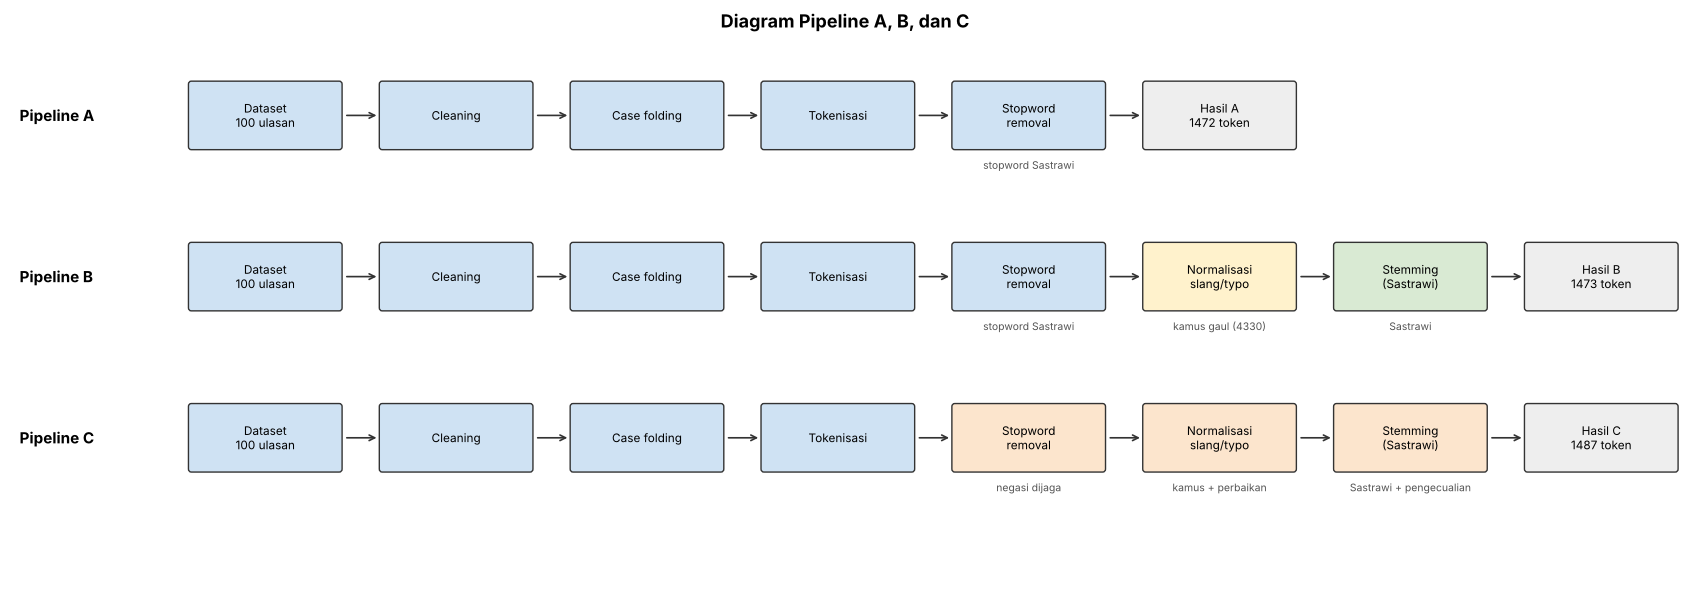

In [34]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def kotak(ax, x, y, teks_k, warna, w=1.55, h=0.62):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.03', fc=warna, ec='#333333', lw=1))
    ax.text(x + w / 2, y + h / 2, teks_k, ha='center', va='center', fontsize=8.5)

def panah(ax, x1, x2, y):
    ax.annotate('', xy=(x2, y + 0.31), xytext=(x1, y + 0.31),
                arrowprops=dict(arrowstyle='->', color='#333333', lw=1.2))

fig, ax = plt.subplots(figsize=(17, 6.2))
ax.set_xlim(-1.9, 15.6)
ax.set_ylim(-0.4, 5.2)
ax.axis('off')

biru, hijau, kuning, oranye, abu = '#cfe2f3', '#d9ead3', '#fff2cc', '#fce5cd', '#eeeeee'
langkah = ['Dataset\n100 ulasan', 'Cleaning', 'Case folding', 'Tokenisasi', 'Stopword\nremoval',
           'Normalisasi\nslang/typo', 'Stemming\n(Sastrawi)', 'Hasil']
lajur = [
    ('Pipeline A', 4.1, [True, True, True, True, True, False, False], ['', '', '', '', 'stopword Sastrawi', '', ''], 'Hasil A\n1472 token'),
    ('Pipeline B', 2.5, [True] * 7, ['', '', '', '', 'stopword Sastrawi', 'kamus gaul (4330)', 'Sastrawi'], 'Hasil B\n1473 token'),
    ('Pipeline C', 0.9, [True] * 7, ['', '', '', '', 'negasi dijaga', 'kamus + perbaikan', 'Sastrawi + pengecualian'], 'Hasil C\n1487 token'),
]
for nama, y, aktif, catatan, hasil_teks in lajur:
    ax.text(-1.8, y + 0.31, nama, fontsize=11, fontweight='bold', va='center')
    for i, nm in enumerate(langkah[:7]):
        x = i * 2.0
        if aktif[i]:
            warna = biru if i < 5 else (kuning if i == 5 else hijau)
            if nama == 'Pipeline C' and i >= 4:
                warna = oranye
            kotak(ax, x, y, nm, warna)
            if catatan[i]:
                ax.text(x + 0.775, y - 0.12, catatan[i], ha='center', va='top', fontsize=7.5, color='#555555')
            if i < 6 and (i < 4 or aktif[i + 1]):
                panah(ax, x + 1.6, x + 1.97, y)
    # kotak hasil
    n_aktif = sum(aktif)
    x_akhir = (n_aktif - 1) * 2.0
    panah(ax, x_akhir + 1.6, x_akhir + 1.97, y)
    kotak(ax, x_akhir + 2.0, y, hasil_teks, abu)

ax.set_title('Diagram Pipeline A, B, dan C', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('diagram_pipeline.png', dpi=150, bbox_inches='tight')
plt.show()

---
# BAGIAN 8 - CONTOH ANALISIS (14 contoh)
Semua jumlah dihitung dari data, bukan diketik manual.

In [35]:
def asal_ke_hasil(kolom_asal, kata_asal):
    # kata hasil dari token asal tertentu di Pipeline B
    h = tabel[tabel[kolom_asal] == kata_asal]
    return h['stem'].mode().iloc[0] if len(h) else '-'

def jml(kolom, nilai):
    return int((tabel[kolom] == nilai).sum())

# kata-kata typo yang masih tersisa di hasil B
typo = ['igin', 'bagis', 'donwload', 'alngkah', 'nyape']
sisa_typo = {k: int(sum(1 for kal in b_hasil for w in kal if w == k)) for k in typo}

# duplikat ulasan
dup = int(df['reviewContent'].duplicated(keep=False).sum())
unik_dup = int(df['reviewContent'].nunique())

# emotikon di isi dan judul ulasan
pola_emotikon = r'(:\)|:\(|: \(|:v|\^_\^)'
n_emotikon = int(df['reviewContent'].str.contains(pola_emotikon, regex=True).sum())

contoh_analisis = pd.DataFrame([
 (1,  'Stopword', 'tidak ada kendala', ' '.join(a_hasil[34][-2:]), 'SALAH', 'negasi `tidak` dibuang, "kendala" jadi terbaca ada masalah', stop_hitung['tidak']),
 (2,  'Stopword', 'tanpa sedikit cacat', ' '.join(a_hasil[52][-3:-1]), 'SALAH', '`tanpa` dibuang, ulasan puas jadi tampak mengeluh cacat', stop_hitung['tanpa']),
 (3,  'Normalisasi', 'udah / yg', 'sudah / yang', 'BENAR', 'singkatan umum dibakukan, kosakata menyatu', jml('asal', 'udah') + jml('asal', 'yg')),
 (4,  'Normalisasi', 'rapih / rapi', asal_ke_hasil('asal', 'rapih'), 'BENAR', 'dua ejaan satu makna disatukan, penting untuk hitung frekuensi', jml('asal', 'rapih')),
 (5,  'Normalisasi', 'mantappp', asal_ke_hasil('asal', 'mantappp'), 'BENAR', 'huruf berulang diringkas lalu cocok dengan kata dasar', jml('asal', 'mantappp')),
 (6,  'Normalisasi', 'add', 'ada', 'SALAH', 'kata Inggris (add WhatsApp) dikira singkatan `ada`', jml('asal', 'add')),
 (7,  'Normalisasi', 'ga / g / gak', 'enggak', 'KURANG', 'masih bentuk gaul, bentuk bakunya `tidak`', jml('normal', 'enggak')),
 (8,  'Stemming', 'pengiriman', asal_ke_hasil('normal', 'pengiriman'), 'BENAR', 'imbuhan peng-an dipotong, kata dasar tepat', jml('normal', 'pengiriman')),
 (9,  'Stemming', 'laptopnya / barangnya', asal_ke_hasil('normal', 'laptopnya') + ' / ' + asal_ke_hasil('normal', 'barangnya'), 'BENAR', 'akhiran -nya dipotong, frekuensi `laptop` dan `barang` jadi akurat', jml('normal', 'laptopnya') + jml('normal', 'barangnya')),
 (10, 'Stemming', 'memuaskan / silakan', asal_ke_hasil('normal', 'memuaskan') + ' / ' + asal_ke_hasil('normal', 'silakan'), 'OVER-STEMMING', 'terpotong terlalu jauh (harusnya puas / silakan)', jml('normal', 'memuaskan') + jml('normal', 'silakan')),
 (11, 'Stemming', 'ternyata / semoga', asal_ke_hasil('normal', 'ternyata') + ' / ' + asal_ke_hasil('normal', 'semoga'), 'OVER-STEMMING', 'makna bergeser, ter- dan se- bukan imbuhan di sini', jml('normal', 'ternyata') + jml('normal', 'semoga')),
 (12, 'Stemming', 'packingnya', stemmer.stem('packingnya'), 'UNDER-STEMMING', 'kata serapan Inggris + -nya tidak dikenali kamus Sastrawi, akhiran tersisa', jml('normal', 'packingnya')),
 (13, 'Typo', ', '.join(k for k in typo if sisa_typo[k] > 0), 'tidak berubah', 'UNDER-NORMALISASI', 'kamus gaul tidak memuat typo, kata ini masih beda dari kata bakunya', sum(sisa_typo.values())),
 (14, 'Data', 'ulasan duplikat (spam reseller)', f'{unik_dup} unik dari 100', 'CATATAN', f'{dup} ulasan punya teks kembar (hanya {unik_dup} teks unik dari 100), frekuensi kata jadi membengkak', dup),
], columns=['no', 'tahap', 'contoh', 'hasil', 'penilaian', 'analisis', 'jumlah'])
pd.set_option('display.max_colwidth', 70)
contoh_analisis

/tmp/ipykernel_760/3438115787.py:19: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  n_emotikon = int(df['reviewContent'].str.contains(pola_emotikon, regex=True).sum())


,no,tahap,contoh,hasil,penilaian,analisis,jumlah
0,1,Stopword,tidak ada kendala,semoga kendala,SALAH,"negasi `tidak` dibuang, ""kendala"" jadi terbaca ada masalah",12
1,2,Stopword,tanpa sedikit cacat,sedikit cacat,SALAH,"`tanpa` dibuang, ulasan puas jadi tampak mengeluh cacat",2
2,3,Normalisasi,udah / yg,sudah / yang,BENAR,"singkatan umum dibakukan, kosakata menyatu",19
3,4,Normalisasi,rapih / rapi,rapi,BENAR,"dua ejaan satu makna disatukan, penting untuk hitung frekuensi",6
4,5,Normalisasi,mantappp,mantap,BENAR,huruf berulang diringkas lalu cocok dengan kata dasar,1
5,6,Normalisasi,add,ada,SALAH,kata Inggris (add WhatsApp) dikira singkatan `ada`,10
6,7,Normalisasi,ga / g / gak,enggak,KURANG,"masih bentuk gaul, bentuk bakunya `tidak`",14
7,8,Stemming,pengiriman,kirim,BENAR,"imbuhan peng-an dipotong, kata dasar tepat",14
8,9,Stemming,laptopnya / barangnya,laptop / barang,BENAR,"akhiran -nya dipotong, frekuensi `laptop` dan `barang` jadi akurat",10
9,10,Stemming,memuaskan / silakan,muas / sila,OVER-STEMMING,terpotong terlalu jauh (harusnya puas / silakan),16


In [36]:
print('Typo tersisa di hasil B:', sisa_typo)
print('Ulasan dengan emotikon di isi ulasan:', n_emotikon)

Typo tersisa di hasil B: {'igin': 1, 'bagis': 1, 'donwload': 1, 'alngkah': 1, 'nyape': 1}
Ulasan dengan emotikon di isi ulasan: 3


---
# BAGIAN 9 - DAMPAK PENGHAPUSAN EMOJI
Dataset ini tidak berisi emoji sama sekali. Jadi dampak penghapusan emoji diuji dua cara: (1) menghitung emoji/emotikon yang ada di dataset, (2) contoh buatan (bukan dari dataset) untuk melihat apa yang hilang.

In [37]:
pola_emoji = re.compile('[\U0001F300-\U0001FAFF\u2600-\u27BF]')
semua_teks = df['reviewContent'].tolist() + df['reviewTitle'].tolist()
print('Emoji (unicode) di isi + judul ulasan:', sum(1 for t in semua_teks if pola_emoji.search(t)))
print('Emotikon teks (:) :v ^_^ : ( ) di isi + judul:', sum(1 for t in semua_teks if re.search(pola_emotikon, t)))
print()
for t in semua_teks:
    if re.search(pola_emotikon, t):
        print('-', t[:90])

Emoji (unicode) di isi + judul ulasan: 0
Emotikon teks (:) :v ^_^ : ( ) di isi + judul: 5

- Order Mi Notebook Air Gold 12.5 inch sampai sesuai harapan. Barangnya asli, packagingnya a
- Nanti saat udah di beli malah 4 GB :v
- barang ok, lamanya pengiriman sesuai estimasi, seller juga ramah menjawab pertanyaan custo
- Puas bgt ^_^
- Pingin, tapi kagak ada uang : (


In [38]:
# CONTOH BUATAN (bukan dari dataset)
buatan = ['Laptopnya bagus banget 😍👍',
          'Pengiriman lama banget 😡',
          'Barang rusak 😭 kecewa',
          'Barang sampai 👍']
arti_emoji = {'😍': ' suka ', '👍': ' bagus ', '😡': ' marah ', '😭': ' sedih '}

def bersihkan(t):
    t = re.sub(r'[^A-Za-z0-9\s]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip().lower()

def ganti_emoji(t):
    for e, arti in arti_emoji.items():
        t = t.replace(e, arti)
    return bersihkan(t)

pd.DataFrame({
    'asli': buatan,
    'emoji dihapus (cleaning kita)': [bersihkan(t) for t in buatan],
    'emoji diganti teks': [ganti_emoji(t) for t in buatan],
})

,asli,emoji dihapus (cleaning kita),emoji diganti teks
0,Laptopnya bagus banget 😍👍,laptopnya bagus banget,laptopnya bagus banget suka bagus
1,Pengiriman lama banget 😡,pengiriman lama banget,pengiriman lama banget marah
2,Barang rusak 😭 kecewa,barang rusak kecewa,barang rusak sedih kecewa
3,Barang sampai 👍,barang sampai,barang sampai bagus


---
# BAGIAN 10 - ANGKA PENDUKUNG UNTUK JAWABAN

In [39]:
# 1. apakah semua kata harus di-stemming? -> berapa token yang berubah dan berapa yang salah
unik_normal = set(tabel['normal'])
berubah = [k for k in unik_normal if stemmer.stem(k) != k]
print('Kata unik (setelah normalisasi):', len(unik_normal))
print('Kata unik yang diubah stemmer   :', len(berubah))
print('Kata unik tidak diubah          :', len(unik_normal) - len(berubah))

# 2-3. over / under stemming (daftar kata yang terdeteksi)
over = {k: stemmer.stem(k) for k in ['memuaskan', 'silakan', 'pemesanan', 'tiki', 'ternyata', 'semoga'] if k in unik_normal}
print('Over-stemming terdeteksi:', over)
under_cek = sorted(k for k in unik_normal if k.endswith('nya') and stemmer.stem(k).endswith('nya') and k not in ('tanya', 'nya'))
print('Under-stemming (akhiran -nya tersisa):', under_cek)

# 4. slang: berapa token yang benar-benar berubah dan berapa yang salah
print()
print('Token berubah karena normalisasi:', len(beda_norm), 'dari', len(tabel))
salah_norm = len(tabel[(tabel['asal'] == 'add') & (tabel['normal'] == 'ada')]) + \
             len(tabel[(tabel['asal'] == 'd') & (tabel['normal'] == 'ada')]) + \
             len(tabel[(tabel['asal'] == 'it') & (tabel['normal'] == 'itu')])
print('Normalisasi yang salah (add, d, it):', salah_norm)

Kata unik (setelah normalisasi): 632
Kata unik yang diubah stemmer   : 135
Kata unik tidak diubah          : 497
Over-stemming terdeteksi: {'memuaskan': 'muas', 'silakan': 'sila', 'pemesanan': 'mesan', 'tiki': 'tik', 'ternyata': 'nyata', 'semoga': 'moga'}
Under-stemming (akhiran -nya tersisa): ['batrenya', 'chargernya', 'designnya', 'mostnya', 'packagingnya', 'packingnya', 'pkknya', 'sellernya', 'servicenya', 'stocknya', 'windowsnya']

Token berubah karena normalisasi: 141 dari 1473
Normalisasi yang salah (add, d, it): 14


In [40]:
# 6. ringkasan metrik tiga pipeline
ringkas = pd.DataFrame({
    'token': [token_a, token_b, token_c],
    'kosakata': [len(kosakata_a), len(kosakata_b), len(kosakata_c)],
    'negasi bertahan': [jumlah_negasi(a_hasil), jumlah_negasi(b_hasil), jumlah_negasi(c_hasil)],
    'stem salah': [jumlah_kata(a_hasil, salah_stem), jumlah_kata(b_hasil, salah_stem), jumlah_kata(c_hasil, salah_stem)],
}, index=['A', 'B', 'C'])
ringkas['kosakata turun vs A'] = (1 - ringkas['kosakata'] / ringkas.loc['A', 'kosakata']).map('{:.1%}'.format)
ringkas

,token,kosakata,negasi bertahan,stem salah,kosakata turun vs A
A,1472,667,1,0,0.0%
B,1473,571,16,24,14.4%
C,1487,571,32,0,14.4%


---
# BAGIAN 11 - JAWABAN PERTANYAAN ANALISIS

Semua angka di bawah berasal dari output Bagian 3 sampai 10.

### 1. Apakah semua kata harus di-stemming?
**Tidak.** Dari 632 kata unik (setelah normalisasi), Sastrawi hanya mengubah 135 kata (21%), sisanya 497 kata memang sudah berupa kata dasar atau kata yang tidak dikenali (nama, angka, kata serapan). Stemming juga merusak sebagian kata: `memuaskan` menjadi `muas`, `silakan` menjadi `sila`. Stemming berguna kalau tujuannya menyatukan bentuk kata (`pengiriman`, `dikirim` menjadi `kirim`), tapi tidak perlu untuk kata yang maknanya bergantung pada bentuk aslinya, dan tidak perlu kalau modelnya sudah paham konteks (misalnya IndoBERT).

### 2. Apakah terdapat over-stemming?
**Ya.** Enam kata unik terpotong terlalu jauh: `memuaskan` menjadi `muas` (6 token), `silakan` menjadi `sila` (10), `pemesanan` menjadi `mesan` (1), `tiki` menjadi `tik` (1), `ternyata` menjadi `nyata` (2), dan `semoga` menjadi `moga` (6). Penyebabnya, Sastrawi mengenali awalan/akhiran dari pola huruf saja, tanpa tahu apakah kata itu memang berimbuhan.

### 3. Apakah terdapat under-stemming?
**Ya.** Kata serapan atau nama merek yang diberi akhiran `-nya` tidak dipotong karena kata dasarnya tidak ada di kamus Sastrawi: `packingnya`, `chargernya`, `designnya`, `sellernya`, `stocknya`, `windowsnya`, `servicenya`, `packagingnya` (11 kata unik). Akibatnya `packing` dan `packingnya` dihitung sebagai dua kata berbeda. Selain itu, typo seperti `igin`, `bagis`, `donwload`, `alngkah`, `nyape` tidak dikenali kamus gaul maupun stemmer, jadi tetap utuh.

### 4. Apakah slang selalu perlu dinormalisasi?
**Tidak selalu.** Normalisasi mengubah 141 token dan sebagian besar benar (`yg` menjadi `yang` 11x, `udah` menjadi `sudah` 8x, `rapih` menjadi `rapi` 6x, `bgt` menjadi `banget` 5x), sehingga kosakata menyusut dari 667 menjadi 571 kata unik. Tapi kamus gaul bekerja tanpa konteks, jadi ada 14 token yang salah: `add` (kata Inggris) menjadi `ada` 10x, `d` menjadi `ada` 2x, `it` menjadi `itu` 2x. Selain itu `ga/g/gak` menjadi `enggak` (14x) yang masih belum baku. Normalisasi perlu kalau analisis berbasis frekuensi kata atau leksikon sentimen baku. Kalau modelnya dilatih dengan data gaul yang sama, atau slang itu sendiri fitur yang dicari (misal deteksi gaya bahasa), normalisasi bisa dilewati.

### 5. Apa dampak penghapusan emoji?
Pada dataset ini **hampir tidak ada dampak**: tidak ada emoji unicode sama sekali, hanya 5 emotikon teks (`:)`, `:v`, `^_^`, `: (`) di isi dan judul ulasan, dan semuanya terhapus oleh cleaning. Pada contoh buatan di Bagian 9 (bukan dari dataset), dampaknya nyata: `Pengiriman lama banget 😡` kehilangan sinyal marah, dan `Barang sampai 👍` menjadi netral setelah emoji dihapus. Untuk analisis sentimen sebaiknya emoji diubah ke teks (`😡` menjadi `marah`) sebelum cleaning, bukan dibuang.

### 6. Pipeline mana yang menghasilkan data paling sesuai?
Untuk data ulasan ini, **Pipeline C**. Ringkasan metriknya (dari Bagian 10):

| Pipeline | Token | Kosakata | Negasi bertahan (dari 32) | Hasil stem salah |
|---|---|---|---|---|
| A | 1472 | 667 | 1 | 0 (tidak ada stemming) |
| B | 1473 | 571 (turun 14,4%) | 16 | 24 |
| C | 1487 | 571 (turun 14,4%) | 32 | 0 |

- A paling sederhana tapi kosakatanya paling besar (`pengiriman`, `dikirim`, `rapih`, `rapi` dihitung terpisah) dan hampir semua negasi hilang.
- B menyusutkan kosakata, tapi menambah kesalahan stemming dan masih membuang `tidak`, `belum`, `tanpa`.
- C mempertahankan semua negasi dan tidak punya hasil stem salah di daftar yang dicek, dengan kosakata sama kecilnya dengan B.

**Catatan jujur:** kamus perbaikan dan pengecualian di Pipeline C disusun setelah melihat kesalahan di dataset yang sama, jadi angka "0 stem salah" itu hasil rancangan, bukan bukti C akan sebagus itu di data baru. Untuk membuktikannya perlu data lain atau label sentimen untuk mengukur akurasi model.

---
# BAGIAN 12 - KESIMPULAN

1. Urutan preprocessing berpengaruh besar. Stopword removal sebelum normalisasi membuat `ga/g/gak` lolos, sementara `tidak` terbuang.
2. **Negasi adalah masalah paling serius.** Daftar stopword Sastrawi membuang `tidak`, `belum`, `tanpa`, `kecuali`, sehingga "tidak ada kendala" menjadi "kendala" dan maknanya terbalik. Hanya 1 dari 32 token negasi yang bertahan di Pipeline A dan 16 dari 32 di Pipeline B.
3. Normalisasi dan stemming mengurangi kosakata 14,4% (667 menjadi 571), tapi keduanya bekerja tanpa konteks sehingga menghasilkan kesalahan: 14 normalisasi salah (`add`, `d`, `it`), 6 kata over-stemming, 11 kata under-stemming.
4. Dataset berisi 9 ulasan dengan teks kembar (spam reseller), sehingga hanya 93 teks unik dari 100. Duplikat ini membengkakkan frekuensi kata dan sebaiknya dibuang sebelum modeling.
5. Sastrawi jauh lebih cocok untuk bahasa Indonesia dibanding NLTK Porter (Bagian 4), tapi tidak sempurna. Daftar stopword NLTK (757 kata) membuang kata bermakna seperti `baik` dan `sangat`.
6. **Rekomendasi:** Pipeline C (negasi dijaga, normalisasi dengan kamus perbaikan, stemming Sastrawi dengan pengecualian) untuk analisis sentimen ulasan. Untuk hasil lebih baik, tambahkan deteksi duplikat, perbaikan typo (misal berbasis jarak edit), dan pertimbangkan model berbasis konteks yang tidak butuh stemming.

---
# CHECKLIST OUTPUT TUGAS

| Output | Lokasi |
|---|---|
| Dataset | `dataset_ulasan_laptop_100.csv` (100 ulasan) |
| Notebook / source code | notebook ini |
| Tabel Before-After | Bagian 6 (10 contoh) dan `tabel_before_after_100.csv` (100 ulasan) |
| Diagram pipeline | Bagian 7 dan `diagram_pipeline.png` |
| Minimal 10 contoh analisis | Bagian 8 (14 contoh) |
| Jawaban 6 pertanyaan | Bagian 11 |
| Kesimpulan | Bagian 12 |
